# Bibliotecas

In [ ]:
!pip install pymcr
!pip install spectrochempy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 958.4/958.4 kB 10.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 50.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [spectrochempy]


In [ ]:
import plotly.express as px
import plotly.graph_objects as go

from pymcr.mcr import McrAR
from pymcr.regressors import NNLS, OLS
from pymcr.constraints import ConstraintNonneg, Constraint

import numpy as np

from scipy.integrate import odeint
from scipy.optimize import least_squares
from scipy.linalg import svd

from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler

import spectrochempy as scp

import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Funções

In [ ]:
def model(y, t, mechanism, k):
  """
  Generate a list of kinetic equations.

  Parameters
  ----------
  mechanism : string
      Reaction mechanism of the system.

  y : list
      Initial concentrations of the components.

  t : list
      A vector that represents the reaction time.

  k : list
      Reaction rates of the system.
  """

  # Remove os espaços da string do mecanismo
  mechanism = mechanism.replace(" ","")

  # Converte todos os separadores do mecanismo para -, dessa forma usamos
  # list dict.fromkeys para remover as duplicadas dos componentes
  components = mechanism.replace(">","-").replace("+","-").replace(";","-")
  components = list(dict.fromkeys(components.split("-")))

  # Criamos esses dois dicionários com base nos componentes inputados
  # e depois atribuimos as devidas concentrações, e 0 para todas as equações
  concentrations = {}
  equations = {}

  for i in range(len(components)):
    concentrations[components[i]] = y[i]
    equations[components[i]] = 0

  # Separamos cada reação do mecanismo, e criamos a variável kn que vai nos
  # auxiliar a utilizar os devidos k's das reações
  reactions = mechanism.split(";")

  kn = 0
  for n in reactions:

    # Separamos as etapa das reações e rodamos um loop para trabalhar em cada
    # etapa
    stages = n.split(">")
    for i in range(len(stages)):

      # Na primeira etapa, criamos uma lista das concentrações dos componentes
      # presentes nessa etapa, e então para cada componente presente, adicionamos
      # às equações a multiplicação das concentrações * o negativo do primeiro k
      if i == 0:
        values = [concentrations[comp] for comp in stages[i].split("+") if comp in concentrations]
        for j in range(len(values)):
          equations[stages[i].split("+")[j]] += (float(np.prod(values)) * -k[kn])

      # Para a ultima etapa, criamos uma lista das concentrações da etapa anterior (values)
      # e uma lista das concentrações dessa etapa (values2). Para cada componente nessa etapa
      # adicionamos às equações o k anterior * a multiplicação das concentrações da etapa anterior
      elif i == len(stages)-1:
        values = [concentrations[comp] for comp in stages[i-1].split("+") if comp in concentrations]
        values2 = [concentrations[comp] for comp in stages[i].split("+") if comp in concentrations]
        for j in range(len(values2)):
          equations[stages[i].split("+")[j]] += ((float(np.prod(values)) * k[kn-1]))

      # Para as etapas intermediárias, também listamos as concentrações da etapa anterior e da
      # etapa atual, depois rodamos um loop de acordo com a quantidade de componentes nessa etapa
      # e adicionamos às equações a subtração do k anterior * a multiplicação das concentrações da
      # etapa anterior e o k atual * a multiplicação das concentrações da etapa atual.
      else:
        values = [concentrations[comp] for comp in stages[i-1].split("+") if comp in concentrations]
        values2 = [concentrations[comp] for comp in stages[i].split("+") if comp in concentrations]
        for j in range(len(values2)):
          equations[stages[i].split("+")[j]] += ((float(np.prod(values)) * k[kn-1]) - (float(np.prod(values2)) * k[kn]))

      # Para cada etapa que rodamos o loop, incrementamos o kn em 1
      kn += 1
    # Para cada reação que rodamos o loop, diminuimos o kn em 1
    kn -= 1

  return list(equations.values())

In [ ]:
class ConstraintClosure(Constraint):
  """
  Enforce that the sum of components in the system equals 1.

  Parameters
  ----------
  copy : bool
      Make copy of input data, A; otherwise, overwrite (if mutable)
  """
  def __init__(self, copy=False):
      super().__init__(copy)

  def transform(self, A):
    """ Apply closure constraint. """
    for i in range(len(A)):
      s = sum(A[i])
      T = []
      for j in A[i]:
        T.append(j/s)
      A[i] = tuple(T)
    return A

class ConstraintKinetics(Constraint):
  """
  It constrains the component concentrations to conform to a kinetic model.

  Parameters
  ----------
  copy : bool
      Make copy of input data, A: otherwise, overwrite (if mutable)

  kinetics : array
      Known kinetic model
  """
  def __init__(self, mechanism, y, t, k, copy=True):
    super().__init__(copy)
    self.mechanism = mechanism
    self.y = y
    self.t = t
    self.k = k
    self.kin = []
    self.k_hist = []
    self.iter = 0
    self.k_hist.append(k)


  def model(self, y, t, mechanism, k):
    """
    Generate a list of kinetic equations.

    Parameters
    ----------

    y : list
        Initial concentrations of the components.

    t : list
        A vector that represents the reaction time.

    k : list
        Reaction rates of the system.
    """

    # Remove os espaços da string do mecanismo
    mechanism = self.mechanism.replace(" ","")

    # Converte todos os separadores do mecanismo para -, dessa forma usamos
    # list dict.fromkeys para remover as duplicadas dos componentes
    components = mechanism.replace(">","-").replace("+","-").replace(";","-")
    components = list(dict.fromkeys(components.split("-")))

    # Criamos esses dois dicionários com base nos componentes inputados
    # e depois atribuimos as devidas concentrações, e 0 para todas as equações
    concentrations = {}
    equations = {}

    for i in range(len(components)):
      concentrations[components[i]] = y[i]
      equations[components[i]] = 0

    # Separamos cada reação do mecanismo, e criamos a variável kn que vai nos
    # auxiliar a utilizar os devidos k's das reações
    reactions = mechanism.split(";")

    kn = 0
    for n in reactions:

      # Separamos as etapa das reações e rodamos um loop para trabalhar em cada
      # etapa
      stages = n.split(">")
      for i in range(len(stages)):

        # Na primeira etapa, criamos uma lista das concentrações dos componentes
        # presentes nessa etapa, e então para cada componente presente, adicionamos
        # às equações a multiplicação das concentrações * o negativo do primeiro k
        if i == 0:
          values = [concentrations[comp] for comp in stages[i].split("+") if comp in concentrations]
          for j in range(len(values)):
            equations[stages[i].split("+")[j]] += (float(np.prod(values)) * -k[kn])

        # Para a ultima etapa, criamos uma lista das concentrações da etapa anterior (values)
        # e uma lista das concentrações dessa etapa (values2). Para cada componente nessa etapa
        # adicionamos às equações o k anterior * a multiplicação das concentrações da etapa anterior
        elif i == len(stages)-1:
          values = [concentrations[comp] for comp in stages[i-1].split("+") if comp in concentrations]
          values2 = [concentrations[comp] for comp in stages[i].split("+") if comp in concentrations]
          for j in range(len(values2)):
            equations[stages[i].split("+")[j]] += ((float(np.prod(values)) * k[kn-1]))

        # Para as etapas intermediárias, também listamos as concentrações da etapa anterior e da
        # etapa atual, depois rodamos um loop de acordo com a quantidade de componentes nessa etapa
        # e adicionamos às equações a subtração do k anterior * a multiplicação das concentrações da
        # etapa anterior e o k atual * a multiplicação das concentrações da etapa atual.
        else:
          values = [concentrations[comp] for comp in stages[i-1].split("+") if comp in concentrations]
          values2 = [concentrations[comp] for comp in stages[i].split("+") if comp in concentrations]
          for j in range(len(values2)):
            equations[stages[i].split("+")[j]] += ((float(np.prod(values)) * k[kn-1]) - (float(np.prod(values2)) * k[kn]))

        # Para cada etapa que rodamos o loop, incrementamos o kn em 1
        kn += 1
      # Para cada reação que rodamos o loop, diminuimos o kn em 1
      kn -= 1

    return np.array(list(equations.values()))


  def residuals(self, k, y, t, C_exp):
    """
    Solve the system of ODEs to obtain a simulated concentration matrix and
    calculate the corresponding residuals.

    Parameters
    ----------

    k : list
        Reaction rates of the system.

    y : list
        Initial concentrations of the components.

    t : list
        A vector that represents the reaction time.

    C_exp : array
        A matrix that represents the concentration of the components.

    """

    # A função odeint vai gerar uma simulação da cinética, utilizando a concentração
    # inicial dos componentes (y), o vetor de tempo (t), o mecanismo de reação e
    # os k cinéticos.
    C_simulation = odeint(self.model, y, t, args=(self.mechanism, k))

    # Subtraimos a concentração experimental (C_exp; matriz de concentração da iteração atual)
    # pela matriz de concentração simulada (C_simulation) e usamos o .ravel() para converter
    # a matriz em um vetor.
    return (C_exp - C_simulation).ravel()


  def transform(self, A):
    """
    Use least squares to find the k values that minimize the residuals between
    the simulated and experimental concentration matrices, and solve the ODEs to
    obtain a new simulated concentration matrix using the optimized k values.
    The new simulated concentration matrix replaces the experimental matrix.
    """

    if self.copy:
        A_work = A.copy()
    else:
        A_work = A

    # Usamos o least_squares para encontrar valores de k que minimizam o resíduo encontrado na
    # função residuals
    k_fit = least_squares(self.residuals, self.k, args=(self.y, self.t, A_work), bounds=(0, np.inf))
    # Com os valores de k encontrados, geramos uma nova concentração simulada
    C_fit = odeint(self.model, self.y, self.t, args=(self.mechanism, k_fit.x))
    # Salvamos os valores de k encontrados
    self.k = k_fit.x
    self.kin = C_fit
    self.k_hist.append(k_fit.x)
    self.iter += 1

    # Substituimos a matriz de concentração experimental pela matriz simulada.
    lambda_k = 0
    return A - lambda_k * (A - C_fit)

In [ ]:
def matriz_instrumental(D, shift, t, ax=None):

  if not ax:
    fig, ax = plt.subplots(figsize=(7,4))
  else:
    fig = ax.figure

  for i in range(len(t)):
      cor = cmap(i / len(t))

      ax.plot(
          shift,
          D[i, :],
          color=cor,
          linewidth=0.6,    # Linhas finas evitam o "borrão" excessivo
          alpha=0.7         # Transparência essencial para centenas de linhas sobrepostas
      )

  ax.set_ylabel('Intensidade')
  ax.set_xlim(min(shift), max(shift))
  ax.set_xlabel('Deslocamento Raman (cm⁻¹)')

  norm = plt.Normalize(vmin=t.min(), vmax=t.max())

  sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
  sm.set_array([])

  cbar = fig.colorbar(sm, ax=ax)
  cbar.set_label('Tempo (s)')

  return fig

In [ ]:
def elbow_plot(D, n=10, ax=None):

  if not ax:
    fig, ax = plt.subplots(figsize=(7,4))
  else:
    fig = ax.figure

  X_centrado = D - np.mean(D, axis=0)

  valores_singulares = svd(X_centrado, compute_uv=False)

  ax.plot(range(1, len(valores_singulares[:n]) + 1), valores_singulares[:n], marker='o', color=cmap(1), lw=1.5)
  ax.set_title('Método do Cotovelo (Scree Plot via SVD)')
  ax.set_xlabel('Número de Componentes / Ordem do Valor Singular')
  ax.set_ylabel(r'Valor Singular ($\sigma_i$)')

  return fig

In [ ]:
def initial_estimate(D, n_components, ax=None):

  if not ax:
    fig, ax = plt.subplots(figsize=(7,4))
  else:
    fig = ax.figure

  efa = scp.EFA()
  efa.fit(D)
  efa.n_components = n_components
  C0 = efa.transform(D).data

  exp = round(np.log10(C0.max()))

  l = 0
  colors = []
  while l <= n_components:
    colors.append(cmap(l/n_components))
    l += n_components/(n_components-1)

  for i, cor in enumerate(colors):
    ax.plot(
        time,
        C0[:, i] / (10**exp),
        color=cor,
        label=['A_estimativa', 'B_estimativa', 'C_estimativa'][i]
    )

  ax.set_ylabel(f'''Concentração estimada ($x 10^{exp:.0f}$)''')
  ax.set_xlim(0, time.max())
  ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
  ax.set_ylim(0, (C0.max()/(10**exp))*1.4)

  ax.set_xlabel('Tempo (s)')

  ax.legend()

  return fig, C0

In [ ]:
def parameter_adjustment(mechanism, y, t, k, C_init, ax=None):

  if not ax:
    fig, ax = plt.subplots(figsize=(7,4))
  else:
    fig = ax.figure

  C_k = odeint(model, y, t, args=(mechanism, k))

  mechanism = mechanism.replace(" ","")
  components = mechanism.replace(">","-").replace("+","-").replace(";","-")
  components = list(dict.fromkeys(components.split("-")))

  comparacao = []

  for i in range(len(C_init)):
    s = C_init[i].sum()
    for j in range(len(C_init[i])):
      C_init[i][j] = C_init[i][j]/s

  for i in range(len(C_k)):
    comparacao.append(np.append(C_init[i], C_k[i]))

  meus_tracos = ['-'] * len(components) + ['--'] * len(components)
  l = 0
  colors = []
  while l <= len(components):
    colors.append(cmap(l/len(components)))
    l += len(components)/(len(components)-1)
  rotulo = [f'{i}_estimado' for i in components] + [f'{i}_simulado' for i in components]

  for i, style in enumerate(meus_tracos):
    ax.plot(t, np.array(comparacao)[:, i], linestyle=style, color=colors[i%len(components)], label=rotulo[i], linewidth=1)

  ax.set_ylabel('Concentração relativa')
  ax.set_xlim(0, t.max())
  ax.set_ylim(0, 1)
  ax.set_xlabel('Tempo (s)')
  ax.legend(loc='upper center', ncol=2)

  return fig

In [ ]:
def mcr_decomposition(D, C_init, t, k, max_iter, noise, mechanism, ax_C=None, ax_ST=None):

  if not ax_C and not ax_ST:
    fig, (ax_C, ax_ST) = plt.subplots(figsize=[6, 8], nrows=2, ncols=1, sharex=False)
  else:
    fig = ax_C.figure

  kinetic = ConstraintKinetics(mechanism, y, t, k)

  mcrark = McrAR(max_iter=max_iter, st_regr=NNLS(), c_regr=NNLS(),
                st_constraints=[ConstraintNonneg()],
                c_constraints=[ConstraintNonneg(), ConstraintClosure(), kinetic],
                tol_increase=1, # Fator de aumento permitido no atributo err. Defina como 0 para nenhum aumento permitido. Por exemplo, definir como 1,0 significa que o err pode dobrar por iteração
                tol_err_change=noise, # Se a variação de erro for menor que tol_err_change por iteração, interrompa o processo.
                tol_n_increase=max_iter,
                tol_n_above_min=max_iter,
                )

  mcrark.fit(D, C=C_init)

  mechanism = mechanism.replace(" ","")
  components = mechanism.replace(">","-").replace("+","-").replace(";","-")
  components = list(dict.fromkeys(components.split("-")))

  if ax_C:
    meus_tracos = ['-'] * len(components)
  l = 0
  colors = []
  while l <= len(components):
    colors.append(cmap(l/len(components)))
    l += len(components)/(len(components)-1)
  rotulo = [f'{i}_recuperado' for i in components]


  for i, style in enumerate(meus_tracos):
    ax_C.plot(t, kinetic.kin[:, i], linestyle=style, color=colors[i%len(components)], label=rotulo[i])

  ax_C.set_ylabel('Concentração relativa')
  ax_C.set_xlim(0, t.max())
  ax_C.set_ylim(0, 1)
  ax_C.set_xlabel('Tempo (s)')
  ax_C.legend()


  for i, style in enumerate(meus_tracos):
    ax_ST.plot(shift, mcrark.ST_.T[:, i], linestyle=style, color=colors[i%len(components)], label=rotulo[i])

  ax_ST.set_ylabel('Intensidade')
  ax_ST.set_xlim(shift.min(), shift.max())
  ax_ST.set_ylim(0, mcrark.ST_.max()*1.2)
  ax_ST.set_xlabel('Deslocamento Raman (cm⁻¹)')
  ax_ST.legend()

  r2 = r2_score(D.flatten(), mcrark.D_.flatten())
  lof = 100 * np.sqrt(np.sum((D - mcrark.D_)**2)/np.sum(D**2))

  return mcrark, kinetic, r2, lof, fig

# Exemplo de uso

In [ ]:
#Configuração padrão dos gráficos

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica"],
    "font.size": 9,          # Tamanho base da fonte
    "axes.labelsize": 10,    # Tamanho do rótulo dos eixos (X e Y)
    "axes.titlesize": 10,    # Tamanho do título (se houver)
    "xtick.labelsize": 8,    # Tamanho dos números do eixo X
    "ytick.labelsize": 8,    # Tamanho dos números do eixo Y
    "legend.fontsize": 8,    # Tamanho da legenda
    "axes.linewidth": 0.8,   # Espessura das linhas das bordas (spines)
    "xtick.direction": "in", # Marcações do eixo X para dentro
    "ytick.direction": "in", # Marcações do eixo Y para dentro
    "xtick.top": True,       # Marcações no topo do eixo X (caixa fechada)
    "ytick.right": True,     # Marcações na direita do eixo Y (caixa fechada)
})

cmap = cm.get_cmap('jet') # Coloração dos gráficos

 WARNING | (MatplotlibDeprecationWarning) The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.


In [ ]:
# Carregamento dos dados
time = # Vetor temporal (s)
shift = # Vetor de deslocamentos Raman (cm⁻¹)
D = # Matriz instrumental

Change in err below tol_err_change (9.2359e-02). Exiting.


INFO:pymcr.mcr:Change in err below tol_err_change (9.2359e-02). Exiting.


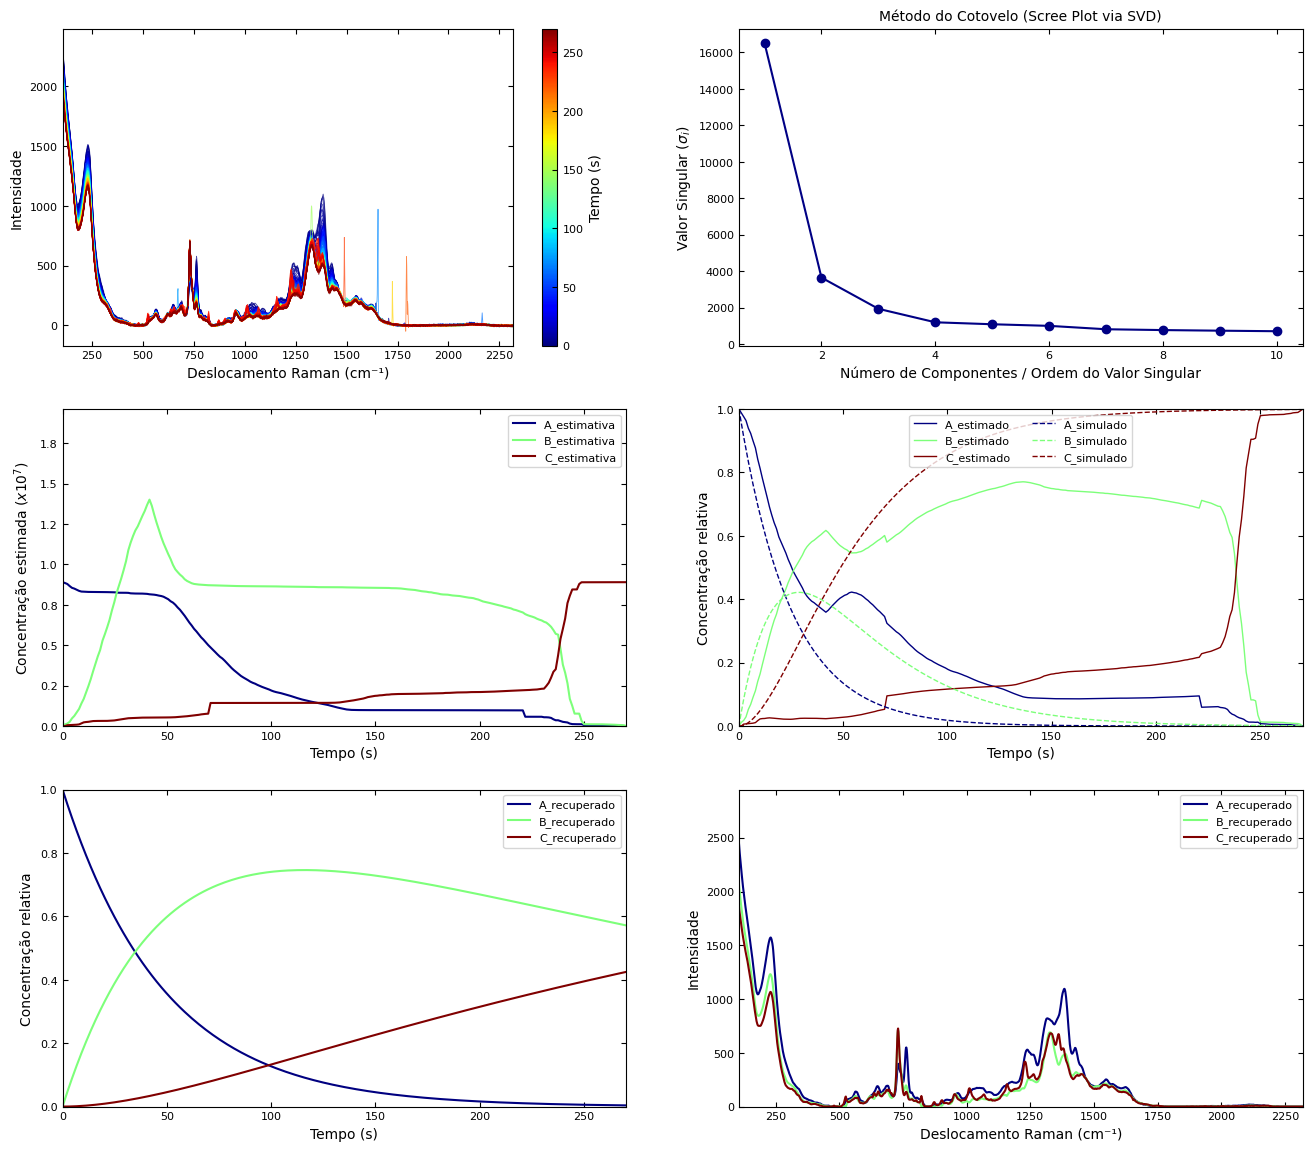

In [ ]:
fig, ((ax1, ax2), (ax3, ax4), (ax5, ax6)) = plt.subplots(figsize=[16,14], nrows=3, ncols=2, sharex=False)

_ = matriz_instrumental(D, shift, time, ax1)
_ = elbow_plot(D, ax=ax2)
_, C_init = initial_estimate(D, 3, ax3)       # A função retorna a estimativa inicial da concentração

mechanism = "A > B > C"                       # Mecanismo reacional
y = [1, 0, 0]                                 # Concentrações iniciais
k = [0.040, 0.030]                            # Chute das constantes cinéticas
_ = parameter_adjustment(mechanism, y, time, k, C_init, ax4)

max_iter = 1000                               # Número máximo de iterações
ruido = 1e-1                                  # Ruído máximo permitido
modelo, cinetica, r2, lof, _ = mcr_decomposition(D, C_init, time, k, max_iter, ruido, mechanism, ax5, ax6)